<img src='./img/up_bann.png' style="display: block; margin: 0 auto;">

*These algorithms come from an **ESA R&D project** and are validated* 

# Mapping solar PV installations with Sentinel-2 ☀️ 🛰️

## Challenge #2 @ 12th CASSINI  Hackathon: Space-enabled crisis response and civil resilience


Can two APEx algorithms detect one solar farm? Do they find the same panels, and how much land do they cover?

This notebook runs two [APEx algorithms](https://algorithm-catalogue.apex.esa.int/) over the same solar farm near Beryslav, in the Kherson Oblast, and compares what each one detects. The farm first appeared in the BSI notebook. If you are new to APEx, start with [APEx 101](./apex_101.ipynb).

By the end of this notebook, you will be able to...

- Run two different algorithms from the APEx Catalogue on the same area and dates
- Retrieve both results and compare them
- Estimate and compare the surface area that each algorithm detects

### **Prerequisites:**

#### 🛠️ Dependencies 
As we will be working with the APEx algorithms, it is important to have a [free CDSE account](https://dataspace.copernicus.eu/ecosystem/join) for the openEO jobs, and installing the following dependencies in your environment besides your desired EO tools:

```text
- git
- git+https://github.com/ESA-APEx/apex_algorithms.git # The up-to-date version of apex_algorithms
- openeo
```
You can make use of the `environment.yml` available in this repository to run all the notebooks!

#### 🛰️ openEO 

As the algorithms run in openEO, it is good to have an understanding of [openEO UDPs](https://open-eo.github.io/openeo-python-client/udp.html). You can find examples that explain how to use the `openeo` library in their [Python Client Examples](https://github.com/Open-EO/openeo-community-examples/tree/main/python).

#### 🔐 Github Authentication 

The `esa_apex_toolbox` library makes use of **Repository access** wich reads remote GitHub content, not local catalogue changes!<br>
You can find more informaiton on how to get your token [here](https://esa-apex.github.io/apex_algorithms/toolbox.html#github-authentication).

If your environment defines `GITHUB_TOKEN`, the token cell below picks it up. Otherwise you will be asked for one, and you can press Enter to continue without it.

With the packages installed, we can start. 🚀 🛰️

### Import Required libraries

In [1]:
%matplotlib inline

import io
from getpass import getpass
import os

from esa_apex_toolbox.algorithms import GithubAlgorithmRepository
import openeo
import rioxarray
import rasterio
import numpy as np
import geopandas as gpd

from shapely.geometry import box
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import folium
from IPython.display import display, HTML

### Costumised functions

This function takes our generated maps and allow us to visualise them side by side by setting titles for each.

In [2]:
def show_maps_side_by_side(map_left, title_left, map_right, title_right, gap="12px"):
    html = f"""
    <div style="display: flex; width: 100%; gap: {gap};">
        <div style="flex: 1; min-width: 0;">
            <h4 style="margin: 0 0 6px 0; text-align: center; font-family: sans-serif;">
                {title_left}
            </h4>
            {map_left._repr_html_()}
        </div>
        <div style="flex: 1; min-width: 0;">
            <h4 style="margin: 0 0 6px 0; text-align: center; font-family: sans-serif;">
                {title_right}
            </h4>
            {map_right._repr_html_()}
        </div>
    </div>
    """
    display(HTML(html))

This function will allow us to visualise our detected solar panels in an interactive map. It reprojects the layer in case the EPSG is not matching target base map EPSG.

In [25]:
def visualising_panels(panel_xarray_layer):

    da_4326 = panel_xarray_layer.rio.reproject("EPSG:4326", resampling=0)  # 0 = nearest neighbor

    # we keep only values larger than 0.95 as detected panels
    is_one = (da_4326 >= 0.95).values

    # we build a transparent RGBA image (H, W, 4)
    rgba = np.zeros((*is_one.shape, 4), dtype=np.float32)
    rgba[is_one] = [0, 0, 0, 220]

    # we add to our basemap
    west, south, east, north = da_4326.rio.bounds()
    m = folium.Map(location=[(south + north) / 2, (west + east) / 2], zoom_start=12)

    folium.raster_layers.ImageOverlay(
        image=rgba,
        bounds=[[south, west], [north, east]],
        name="Detected Mask (1s)",
        interactive=True
    ).add_to(m)

    folium.LayerControl().add_to(m)
    # display(HTML(m._repr_html_()))
    return m

### Authentication

We retrieve our defined system variables:

In [4]:
github_token = os.environ.get('GITHUB_TOKEN') or os.environ.get('GH_TOKEN')
if not github_token:
    github_token = getpass('GitHub token (optional; Enter for unauthenticated access): ') or None

> ##### Remember
> Always **treat a token as a password**: never print it, put it in a committed file, or include it in notebook outputs. Revoke and replace it immediately if exposed; replace it when it expires. Authentication is applied to GitHub API directory requests, not raw catalogue or process-definition downloads.


## 1️⃣ Accessing the algorithms

We access APEx Catalogue metadata

In [5]:
repo = GithubAlgorithmRepository(
    owner='ESA-APEx',
    repo='apex_algorithms',
    folder='algorithm_catalog',
    branch='main',
    token=github_token,
)

We will compare two algorithms that look for solar panels:<br>

- **Solar PV detection** (`solar_pv_detection`): This service detects ground-mounted and rooftop solar PV panels from Sentinel-2 L1C imagery using a deep-learning segmentation model.  It returns two bands: the detected panel pixels, and a probability for each pixel.
- **Photovoltaic Farms Mapping** (`eurac_pv_farm_detection`): This algorithm runs thorugh a training dataset from open-source data to gather PV farm polygons across different countries. It returns one band of detected panels.

We look up each algorithm by its `id`. You can find each `id` on the algorithm's page in the [APEx Catalogue](https://algorithm-catalogue.apex.esa.int/).


In [6]:
spv_algorithm = repo.get_algorithm('solar_pv_detection')
spv_algorithm

Algorithm(id='solar_pv_detection', title='Solar PV detection', description="Detection of solar photovoltaic (PV) installations from Sentinel-2 L1C imagery. The service performs a cloud-free SLIC-based temporal mosaic of Sentinel-2 L1C bands (using Sentinel-2 L2A SCL for cloud masking), normalizes the 13-band composite with training-aligned z-score statistics (per-band mean and standard deviation), and then runs ONNX U-Net inference (256x256 chunks) inside an openEO UDF. Returns a binary 'solar_pv' band and a 'solar_pv_probability' band.", udp_link=UdpLink(href='https://raw.githubusercontent.com/ray-climate/solar_openEO/main/openeo_udp/process_graph/solar_pv_detection_udp.json', title='openEO Process Definition'), service_links=[ServiceLink(href='https://openeofed.dataspace.copernicus.eu', title='CDSE openEO federation')], license=None, organization='Earth RayView Ltd', provider='Earth RayView Ltd', platforms=['CDSE'], keywords=['Energy Production/Use', 'Solar Energy Production/Use', 'Sentinel-2'])

In [7]:
epv_farm_algorithm = repo.get_algorithm('eurac_pv_farm_detection')
epv_farm_algorithm

Algorithm(id='eurac_pv_farm_detection', title='Photovoltaic farms mapping', description='Demonstrator service for the detection of photovoltaic farms. Photovoltaic farms (PV farms) mapping is essential for establishing valid policies regarding natural resources management and clean energy. ', udp_link=UdpLink(href='https://raw.githubusercontent.com/ESA-APEx/apex_algorithms/refs/heads/main/algorithm_catalog/eurac/eurac_pv_farm_detection/openeo_udp/eurac_pv_farm_detection.json', title='openEO Process Definition'), service_links=[ServiceLink(href='https://openeofed.dataspace.copernicus.eu', title='CDSE openEO federation')], license=None, organization='Eurac Research', provider='Eurac Research', platforms=['CDSE'], keywords=['Energy Production/Use', 'Solar Energy Production/Use', 'Sentinel-2'])

Printing the algorithm shows their **title**, **id**, and **related metadata**. We are interested in their parameter `udp_link`, as it will give us access to the **UDP**s we need.
<br>

Each algorithm’s `udp_link` points to the corresponding openEO process within the APEx Catalogue. We take their `href` (the web address), and use it to build our jobs.

In [8]:
spv_link = spv_algorithm.udp_link.href
spv_link

'https://raw.githubusercontent.com/ray-climate/solar_openEO/main/openeo_udp/process_graph/solar_pv_detection_udp.json'

In [9]:
epvf_link = epv_farm_algorithm.udp_link.href
epvf_link

'https://raw.githubusercontent.com/ESA-APEx/apex_algorithms/refs/heads/main/algorithm_catalog/eurac/eurac_pv_farm_detection/openeo_udp/eurac_pv_farm_detection.json'

## 2️⃣ Defining the area and time frame of interest: Beryslav Solar Farm

In the [BSI notebook](./apex_bsi.ipynb), the time series showed a solar farm north of the Kakhovka Dam, near Beryslav in the Kherson Oblast. We use the same area here.

We define a bounding box around the farm. It is about 9 km by 6 km. Check on the map that the red box covers the farm.

In [10]:
geometry = [33.351746,46.840233,33.470535,46.892343]  # west, south, east, north
shape = {'west': geometry[0], 'south': geometry[1], 'east': geometry[2], 'north': geometry[3]}

# to visualise our aoi
aoi = gpd.GeoSeries(box(*geometry), crs='EPSG:4326')
aoi.explore(color='red')

We will run the detection after the Kakhovka Dam collapsed [on 6 June 2023](https://www.bbc.com/news/world-europe-65818705).<br>

We use a single date, the first clear image after the collapse. The [CDSE Browser](https://browser.dataspace.copernicus.eu/) shows clear images on 20 and 21 June 2023, so we use that range. We allow up to 30% cloud cover, because we need one usable scene, not a series.

In [11]:
date_range = ['2023-06-20', '2023-06-21']

## 3️⃣ Running the algorithms in the CDSE openEO federation

We will run **one job** per **algorithm**, through the CDSE openEO federation. Our workflow consist on:

1. Connect to the backend.
2. Solar PV detection: build the process, run the job and access the result.
3. Photovoltaic farms mapping: build the process, run the job and access the result.
4. Acces the results with the help of `rasterio` and `rioxarray`

The first step is connecting to the CDSE openEO federation backend. The first time you run this cell, a browser window opens for you to log in.

In [12]:
connection = openeo.connect("openeofed.dataspace.copernicus.eu").authenticate_oidc() # connecting

Authenticated using refresh token.


Once connected, we define the first job. 

### ☀️🎛️ Solar PV detection job `solar_pv_detection`

To build this job, we pass the algorithm's `process_id`, its location in the catalogue (`namespace`), the date range (`temporal_extent`) and the area of interest (`spatial_extent`). In APEx 101 the same name is passed as the first argument, so the two calls do the same thing.

For more on openEO processes and the CDSE federation, see the [CDSE openEO documentation](https://openeo.org/documentation/1.0/). [APEx 101](./apex_101.ipynb) explains how do user-defined processes work.

We strat with the [Solar PV detection](https://algorithm-catalogue.apex.esa.int/apps/solar_pv_detection#execution-information) algorithm:

In [13]:
solar_pv_re = connection.datacube_from_process(
    process_id="solar_pv_detection", # id
    namespace = spv_link,            # retrieved udp_link
    temporal_extent = date_range,    # defined date_range
    spatial_extent = shape           # our aoi
)

Creating the job sends its definition to the CDSE backend. It does not run the job yet.

In [14]:
# we create and launch only one batch job containing all 7 save nodes
jobpv_re = solar_pv_re.create_job(
        title=f'Solar PV detection er for {date_range[0]} to {date_range[1]}',
        out_format="GTiff")
jobpv_re

<BatchJob job_id='cdse-j-2611251106294a03bb1771e4c3670262'>

With the `start_and_wait` function, we will be able to visualise the progress of our job in the CDSE openEO backend.

In [15]:
jobpv_re.start_and_wait() # with this line we run our job and visualise the results

0:00:00 Job 'cdse-j-2611251106294a03bb1771e4c3670262': send 'start'
0:00:01 Job 'cdse-j-2611251106294a03bb1771e4c3670262': created (progress 0%)
0:00:06 Job 'cdse-j-2611251106294a03bb1771e4c3670262': queued (progress 0%)
0:00:13 Job 'cdse-j-2611251106294a03bb1771e4c3670262': queued (progress 0%)
0:00:22 Job 'cdse-j-2611251106294a03bb1771e4c3670262': queued (progress 0%)
0:00:32 Job 'cdse-j-2611251106294a03bb1771e4c3670262': queued (progress 0%)
0:00:45 Job 'cdse-j-2611251106294a03bb1771e4c3670262': queued (progress 0%)
0:01:01 Job 'cdse-j-2611251106294a03bb1771e4c3670262': queued (progress 0%)
0:01:20 Job 'cdse-j-2611251106294a03bb1771e4c3670262': running (progress N/A)
0:01:44 Job 'cdse-j-2611251106294a03bb1771e4c3670262': running (progress N/A)
0:02:14 Job 'cdse-j-2611251106294a03bb1771e4c3670262': running (progress N/A)
0:02:52 Job 'cdse-j-2611251106294a03bb1771e4c3670262': running (progress N/A)
0:03:41 Job 'cdse-j-2611251106294a03bb1771e4c3670262': finished (progress 100%)


<BatchJob job_id='cdse-j-2611251106294a03bb1771e4c3670262'>

During test runs, the job took about 3 minutes. Your time will depend on the queue and your connection.<br>

When the job finishes, we load its result. `get_results` allows us to access the job's output files, and `get_assets` lists them. The algorithm's catalogue entry specifies that the output are provided in **GeoTiff** rater image that carries its map coordinates. We will access the file and open it with `rioxarray`.

In [16]:
results_a = jobpv_re.get_results()
# get our request
nc_asset_a = next(a for a in results_a.get_assets() if a.key.endswith(".tif"))
asset_url_a = nc_asset_a.href

# we get the Bearer authentication headers from openEO connection
response_a = connection.session.get(asset_url_a)
response_a.raise_for_status()


# stream our netcdf directly into xarray
spv_result = rioxarray.open_rasterio(io.BytesIO(response_a.content))

spv_result

<xarray.DataArray (band: 2, y: 849, x: 1323)> Size: 18MB
[2246454 values with dtype=float64]
Coordinates:
  * band         (band) int64 16B 1 2
  * y            (y) float64 7kB 5.925e+06 5.925e+06 ... 5.916e+06 5.916e+06
  * x            (x) float64 11kB 3.713e+06 3.713e+06 ... 3.726e+06 3.726e+06
    spatial_ref  int64 8B 0
Attributes:
    institution:          Copernicus Data Space Ecosystem openEO API - 0.74.0...
    PROCESSING_SOFTWARE:  0.74.0a15
    AREA_OR_POINT:        Area
    _FillValue:           nan
    scale_factor:         1.0
    add_offset:           0.0
    long_name:            ('solar_pv', 'solar_pv_probability')

The result from the `solar_pv_detection` algorithm is compossed by two **bands**:

- solar_pv : The detected Solar Panel Pixels
- solar_pv_probability : the probability (0-1) of the pixel being a solar panel.

We will visualise the second band, which has index 1 in Python.

### ☀️🎛️ Photovoltaic farms mapping job `eurac_pv_farm_detection`

We use the same period and area as the first job, so the two results can be compared. The only changes are the `process_id` and its `namespace`

In [17]:
e_pv_farm = connection.datacube_from_process(
    process_id="eurac_pv_farm_detection",
    namespace = epvf_link,
    temporal_extent = date_range,
    spatial_extent = shape
)

We generate our job

In [18]:
job_epvf = e_pv_farm.create_job(
        title=f'Solar PV detection er for {date_range[0]} to {date_range[1]}',
        out_format="GTiff")
job_epvf

<BatchJob job_id='cdse-j-26112511101448ecbed8dd20f3e0e8c4'>

Start the job with `start_and_wait`, which shows its progress. On our test runs, this job took about 3 minutes.

In [19]:
job_epvf.start_and_wait() # with this line we run our job and visualise the results 

0:00:00 Job 'cdse-j-26112511101448ecbed8dd20f3e0e8c4': send 'start'
0:00:02 Job 'cdse-j-26112511101448ecbed8dd20f3e0e8c4': created (progress 0%)
0:00:07 Job 'cdse-j-26112511101448ecbed8dd20f3e0e8c4': queued (progress 0%)
0:00:13 Job 'cdse-j-26112511101448ecbed8dd20f3e0e8c4': queued (progress 0%)
0:00:22 Job 'cdse-j-26112511101448ecbed8dd20f3e0e8c4': running (progress N/A)
0:00:32 Job 'cdse-j-26112511101448ecbed8dd20f3e0e8c4': running (progress N/A)
0:00:45 Job 'cdse-j-26112511101448ecbed8dd20f3e0e8c4': running (progress N/A)
0:01:00 Job 'cdse-j-26112511101448ecbed8dd20f3e0e8c4': running (progress N/A)
0:01:20 Job 'cdse-j-26112511101448ecbed8dd20f3e0e8c4': running (progress N/A)
0:01:44 Job 'cdse-j-26112511101448ecbed8dd20f3e0e8c4': finished (progress 100%)


<BatchJob job_id='cdse-j-26112511101448ecbed8dd20f3e0e8c4'>

> ##### Remember
> Run times depend on your connection, the backend and the queue. [APEx](https://apex.esa.int/) prepares the algorithm's process in the background. You submit only the parameters you choose, and retrieve the result 🌍✅


Once the job has finished, we load the **GeoTiff** result in the same way as before.

In [20]:
results_b = job_epvf.get_results()
# get our request
nc_asset_b = next(a for a in results_b.get_assets() if a.key.endswith(".tif"))

# we get the Bearer authentication headers from openEO connection
response_b = connection.session.get(nc_asset_b.href)
response_b.raise_for_status()

# stream our netcdf directly into xarray
epvf_result = rioxarray.open_rasterio(io.BytesIO(response_b.content))

epvf_result

<xarray.DataArray (band: 1, y: 584, x: 909)> Size: 2MB
[530856 values with dtype=float32]
Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 5kB 5.193e+06 5.193e+06 ... 5.187e+06 5.187e+06
  * x            (x) float64 7kB 5.268e+05 5.268e+05 ... 5.359e+05 5.359e+05
    spatial_ref  int64 8B 0
Attributes:
    institution:          Copernicus Data Space Ecosystem openEO API - 0.74.0...
    PROCESSING_SOFTWARE:  0.74.0a15
    AREA_OR_POINT:        Area
    _FillValue:           nan
    scale_factor:         1.0
    add_offset:           0.0

We can see, that this result is different It has one band, and its pixels hold the detected solar panels.

> ##### Remember
> Both algorithms detect solar panels in the same area and period, but each follows its own **UDP**. Check the backend each one runs on, because the algorithms may differ in how they are run.


## 4️⃣ Visualising the detected solar panels

Before you look at the maps, **predict**: where do you expect the two algorithms to find panels, and where would they disagree? 🤔

We use the helper functions from the setup to draw both results on the same basemap. The left map shows the Solar PV probability, where values of 0.95 or higher are shown as panels. The right map shows the binary panel result. The two maps are different kinds of data, so compare their extent and shape rather than their exact values.


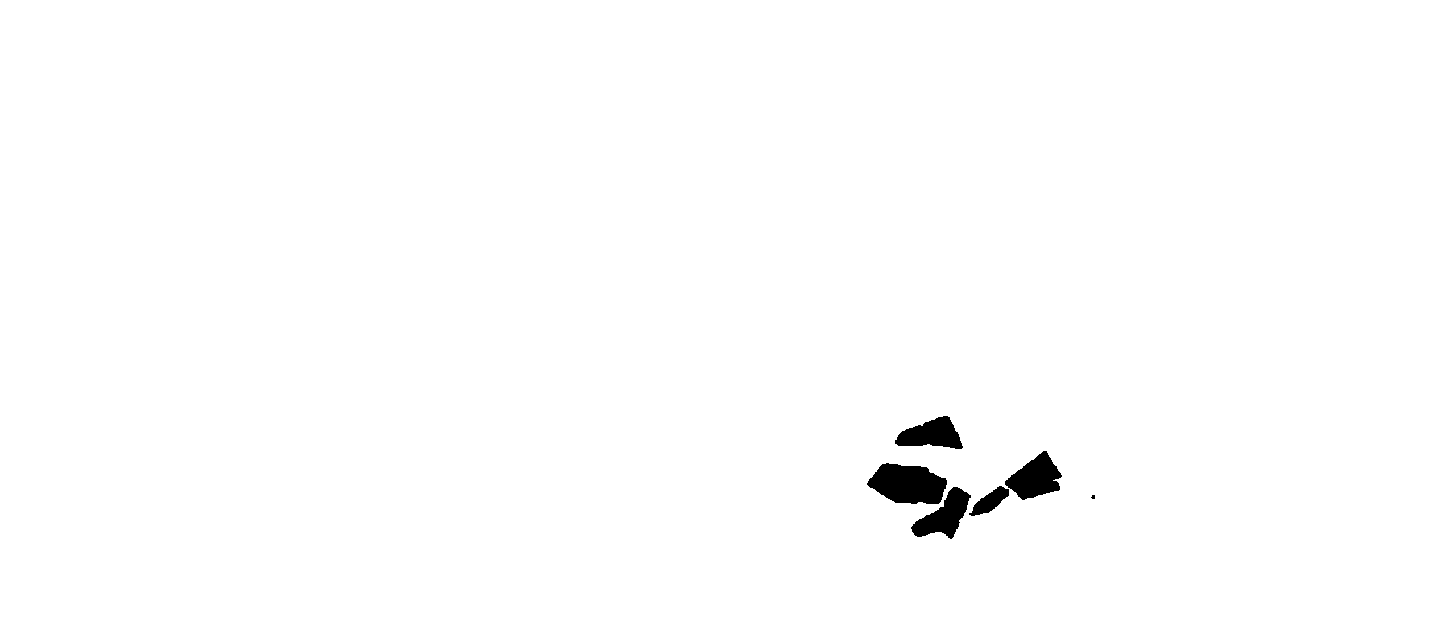
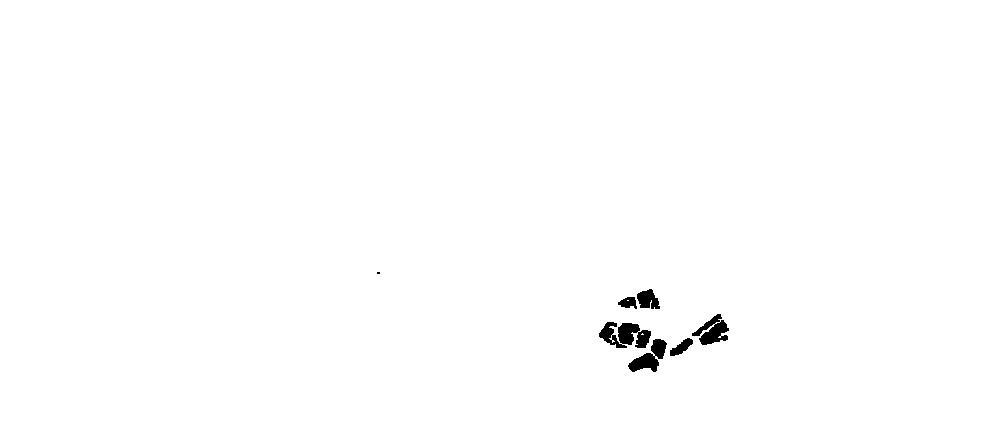

In [26]:
# Call your existing functions directly
m1 = visualising_panels(spv_result[1])
m2 = visualising_panels(epvf_result[0])

show_maps_side_by_side(m1, "Solar PV detection algorithm", m2, "Photovoltaic farms mapping algorithm")

**How to read the maps**: 

- Black areas are pixels detected as solar panels.
- Where the two maps overlap, both algorithms agree.

We can see that both algorithms detected a cluster of panels in the same area. The level of detail differs: one result has finer outlines than the other.

### 👓 Optical check: RGB image

Optical images give a second view of the same area. They depend on cloud-free skies, so the usefulness of the optical check depends on the day.

We downloaded a Sentinel-2 true-colour image (TCI) from the [CDSE Browser](https://browser.dataspace.copernicus.eu/) for 20 June 2023. Each pixel covers 10 by 10 metres. The day matches the start of the detection period.

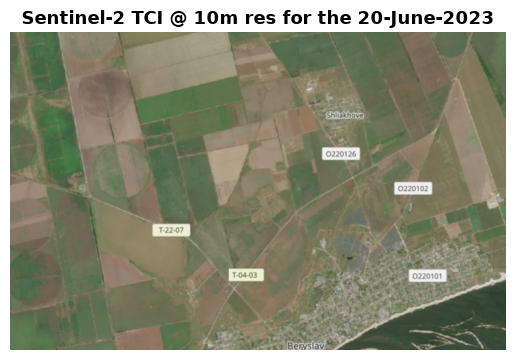

In [22]:
img_farm = mpimg.imread("./img/solar_farm.png")
#  side by side
plt.imshow(img_farm)
plt.title("Sentinel-2 TCI @ 10m res for the 20-June-2023", fontsize=13, fontweight="bold")
plt.axis("off")
plt.show()

The image shows a cluster of solar panels in the detected area. Compare its outline with the two maps above. Small artefacts can appear in the masks, so check them against this image before you trust a single pixel.

## 5️⃣ Comparing the detected area

Finally, to compare the detected surface we will:

- Open each GeoTIFF
- Read its pixel size from the metadata. Pixels are square, so one value is enough.
- Count the pixels detected as panels, which have the value 1
- Convert the count to hectares: 

$$
\text{Detected area (ha)} = \frac{\text{detected pixels} \times \text{pixel area (m}^2\text{)}}{10{,}000}
$$

where the pixel area is the square of the pixel size in metres:

$$
\text{pixel area (m}^2\text{)} = \text{resolution (m)} \times \text{resolution (m)}
$$

In [23]:
spv_tiff = rasterio.open(io.BytesIO(response_a.content))
resolution1 = spv_tiff.res[0]
count_ones = int((spv_result[0] ==1).sum())
total_detected_area_1 = (count_ones * (resolution1*resolution1) )/ 10000

print(f"Resolution:      {resolution1:.0f} m")
print(f'The total detected area with the solar_pv_detection algorithm is {total_detected_area_1} ha')

Resolution:      10 m
The total detected area with the solar_pv_detection algorithm is 95.08 ha


In [24]:
epvf_tiff = rasterio.open(io.BytesIO(response_b.content))
resolution2 = epvf_tiff.res[0]
count_ones_epvf = int((epvf_result[0] == 1).sum())
total_detected_area_2 = (count_ones_epvf * (resolution2*resolution2) )/ 10000

print(f"Resolution:      {epvf_tiff.res[0]:.0f} m")
print(f'The total detected area with the eurac_pv_farm_detection algorithm is {total_detected_area_2} ha')


Resolution:      10 m
The total detected area with the eurac_pv_farm_detection algorithm is 33.47 ha


Each cell prints the pixel size and the total area in hectares. Compare the two areas.

**Questions to answer**
- Which algorithm reports more area? The `solar_pv_detection` algorithm. It detects 60ha more.
- Which result does the TCI support better? Both results have their advantage. One provides detailing among the main roads of the farm. The other one detects clusters and seems that depending on the size of the paths in between the solar panels the ground is detected or not.

**Limits**
- The areas cover only the bounding box we defined.
- We have no reference data, so the comparison shows how much each algorithm detects, not which one is more accurate.

## 6️⃣ Takeaways



In this notebook you ran two [APEx algorithms](https://algorithm-catalogue.apex.esa.int/) over the same area and dates, retrieved both results, and compared the detected area. 

You can reuse this workflow for any place or event:

1. **Run both algorithms on the same area and dates**: Shared inputs make the results comparable, but each algorithm still uses its own method.
2. **Visualise the results**: One algorithm may show more detail, and the other may give cleaner boundaries. Check which one matches the optical image.
3. **Compare**: Where do the algorithms agree, and where do they differ? Treat each difference as a question to answer with the imagery, not as a verdict on either algorithm.

To use another area or event, change the area and the dates. The steps stay the same. Check each algorithm's inputs first, because other algorithms take different parameters.


## Ready for the next application?

[APEx](https://apex.esa.int/) gives you a catalogue of ESA-validated Earth observation algorithms process directly Sentinel data.<br>

Choose an algorithm, define your area and dates, and the cloud platform returns a result you can map and analyse. @ the [12th CASSINI Hackathon](https://www.cassini.eu/hackathons/), you decide what to recognise and what to act on.

<img src='./img/low_bann.png' style="display: block; margin: 0 auto;">